# 03 – Random Forest
Random Forest classifier for predicting hotel booking cancellations (MS26936130).
Uses the same train/test split as the Logistic Regression notebook (created in notebook 01).

In [7]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42

In [8]:
# load the train/test sets created in notebook 01 (same split for both models)
train = pd.read_csv("../outputs/train.csv")
test = pd.read_csv("../outputs/test.csv")

X_train = train.drop(columns=["is_canceled"])
y_train = train["is_canceled"]
X_test = test.drop(columns=["is_canceled"])
y_test = test["is_canceled"]

print(X_train.shape, X_test.shape)

(69767, 31) (17442, 31)


In [9]:
# text columns need one-hot encoding; numeric columns are used as they are
cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

print("Categorical:", cat_cols)
print("Numeric:", len(num_cols), "columns")

Categorical: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']
Numeric: 22 columns


## Baseline model
A Random Forest with default settings, as a starting point before tuning.
Categorical columns are one-hot encoded inside a pipeline, so the encoder is fitted on the training data only (no leakage). Rare categories (fewer than 50 bookings, e.g. small countries) are grouped together. No scaling is needed, because tree-based models are not affected by the scale of features.

In [10]:
# preprocessing: one-hot encode text columns, pass numeric columns through unchanged
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat_cols),
    ("num", "passthrough", num_cols),
])

# full pipeline: preprocessing + Random Forest
rf_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

In [19]:
start = time.time()
rf_pipeline.fit(X_train, y_train)
print("Training time:", round(time.time() - start, 1), "s")

y_pred = rf_pipeline.predict(X_test)
y_prob = rf_pipeline.predict_proba(X_test)[:, 1]   # probability of "canceled"

print("Train accuracy:", round(accuracy_score(y_train, rf_pipeline.predict(X_train)), 4))
print("Test accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision     :", round(float(precision_score(y_test, y_pred)), 4))
print("Recall        :", round(recall_score(y_test, y_pred), 4))
print("F1-score      :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC       :", round(roc_auc_score(y_test, y_prob), 4))

Training time: 34.6 s
Train accuracy: 0.997
Test accuracy : 0.8404
Precision     : 0.763
Recall        : 0.6092
F1-score      : 0.6775
ROC-AUC       : 0.8974


## Hyperparameter tuning
The baseline overfits (train accuracy 0.997 vs test accuracy 0.840) and misses about 39% of cancellations (recall 0.61). Hyperparameters are tuned with randomized search and stratified 3-fold cross-validation on the training set only, using F1-score as the selection metric because the classes are imbalanced. The test set is not used during tuning.

In [13]:
# hyperparameters to try ("model__" refers to the Random Forest step in the pipeline)
param_dist = {
    "model__n_estimators": [100, 200, 300],      # number of trees
    "model__max_depth": [10, 20, 30, None],      # maximum depth of each tree
    "model__min_samples_leaf": [1, 2, 5],        # minimum bookings in a leaf (limits overfitting)
    "model__max_features": ["sqrt", "log2"],     # features considered at each split
    "model__class_weight": [None, "balanced"],   # "balanced" gives more weight to cancellations
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    rf_pipeline, param_dist,
    n_iter=10,              # try 10 random combinations
    scoring="f1",           # choose the best by F1 on the validation folds
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

start = time.time()
search.fit(X_train, y_train)
print("Tuning time:", round(time.time() - start, 1), "s")
print("Best parameters:", search.best_params_)
print("Best CV F1:", round(search.best_score_, 4))

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Tuning time: 452.5 s
Best parameters: {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model__class_weight': 'balanced'}
Best CV F1: 0.7027


## Tuned model: test-set evaluation
The best model from the search is evaluated once on the untouched test set.

In [17]:
def evaluate(model, X_train, y_train, X_test, y_test):
    """Print train accuracy and test metrics for a fitted classifier."""
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]   # probability of "canceled"
    results = {
        "Train accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }
    for name, value in results.items():
        print(f"{name:<15}: {float(value):.4f}")
    return results

# baseline metrics again (rf_pipeline is still the fitted baseline), stored for the comparison table
baseline_results = evaluate(rf_pipeline, X_train, y_train, X_test, y_test)

Train accuracy : 0.9970
Test accuracy  : 0.8404
Precision      : 0.7630
Recall         : 0.6092
F1-score       : 0.6775
ROC-AUC        : 0.8974


In [18]:
best_rf = search.best_estimator_   # already refit on the full training set
tuned_results = evaluate(best_rf, X_train, y_train, X_test, y_test)

Train accuracy : 0.8695
Test accuracy  : 0.8197
Precision      : 0.6394
Recall         : 0.7899
F1-score       : 0.7068
ROC-AUC        : 0.8969


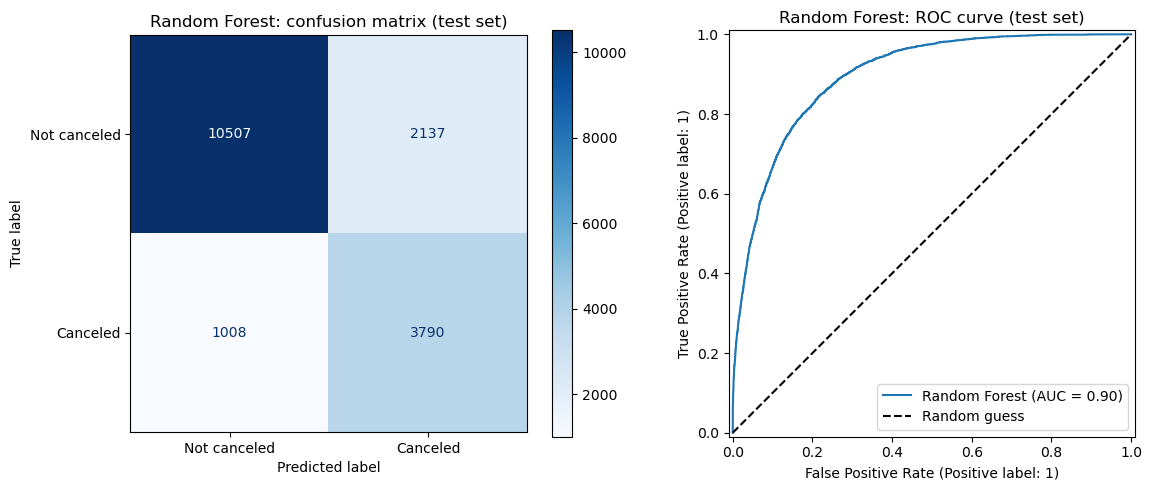

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    best_rf, X_test, y_test, display_labels=["Not canceled", "Canceled"],
    cmap="Blues", ax=axes[0])
axes[0].set_title("Random Forest: confusion matrix (test set)")

RocCurveDisplay.from_estimator(best_rf, X_test, y_test, ax=axes[1], name="Random Forest")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("Random Forest: ROC curve (test set)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/rf_confusion_roc.png", dpi=300, bbox_inches="tight")
plt.show()

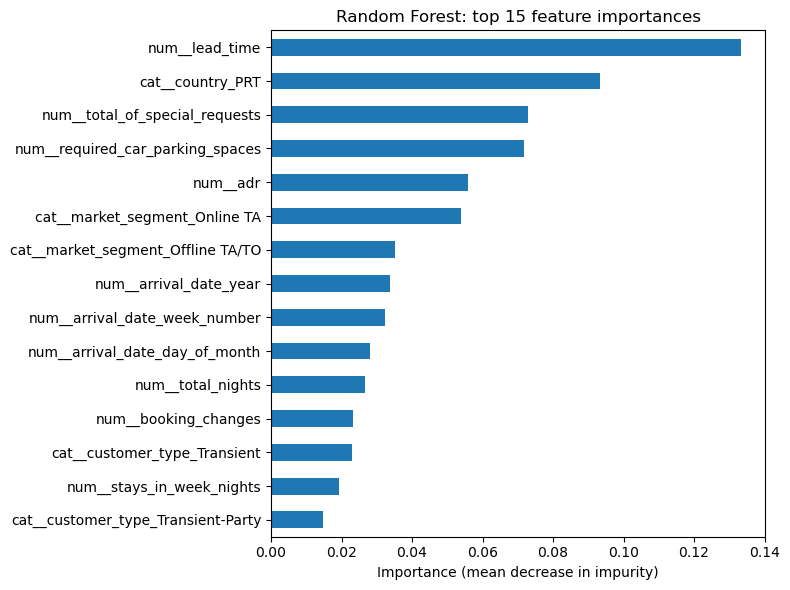

num__lead_time                        0.133440
cat__country_PRT                      0.093293
num__total_of_special_requests        0.072884
num__required_car_parking_spaces      0.071663
num__adr                              0.055786
cat__market_segment_Online TA         0.053778
cat__market_segment_Offline TA/TO     0.035287
num__arrival_date_year                0.033842
num__arrival_date_week_number         0.032227
num__arrival_date_day_of_month        0.027968
num__total_nights                     0.026547
num__booking_changes                  0.023185
cat__customer_type_Transient          0.022921
num__stays_in_week_nights             0.019270
cat__customer_type_Transient-Party    0.014675
dtype: float64

In [21]:
# which features does the forest rely on most?
feature_names = best_rf.named_steps["preprocess"].get_feature_names_out()
importances = pd.Series(best_rf.named_steps["model"].feature_importances_, index=feature_names)
top15 = importances.sort_values(ascending=False).head(15)

top15.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Random Forest: top 15 feature importances")
plt.xlabel("Importance (mean decrease in impurity)")
plt.tight_layout()
plt.savefig("../figures/rf_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

top15

In [22]:
# save metrics so notebook 04 can compare both models
results_df = pd.DataFrame([baseline_results, tuned_results],
                          index=["RF baseline", "RF tuned"])
results_df.to_csv("../outputs/rf_results.csv")
results_df.round(4)

,Train accuracy,Test accuracy,Precision,Recall,F1-score,ROC-AUC
RF baseline,0.9970,0.8404,0.7630,0.6092,0.6775,0.8974
RF tuned,0.8695,0.8197,0.6394,0.7899,0.7068,0.8969
